#**Load Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Hamza - AI ML-Learning/Day_1/data.csv"

df = pd.read_csv(file_path)

print(df.head())
print(df.shape)

Mounted at /content/drive
                  date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000      1963   
4     1.0           0     0          4        1140            800      1976   

   yr_renova

Select the features:

In [2]:
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "yr_built",
    "yr_renovated"
]

X = df[features].copy()
y = df["price"].copy()

# Remove invalid target values
valid = y.notna() & np.isfinite(y) & (y > 0)

X = X.loc[valid]
y = y.loc[valid]

# Convert continuous prices into two classes
price_threshold = y.median()

y = (y > price_threshold).astype(int)

print("Price threshold:", price_threshold)
print("\nClass distribution:")
print(y.value_counts())

Price threshold: 465000.0

Class distribution:
price
0    2286
1    2265
Name: count, dtype: int64


Split training and testing data

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (3640, 10)
Testing: (911, 10)


Preprocess using NumPy

In [4]:
# Convert DataFrames to NumPy arrays
X_train = X_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

y_train = y_train.to_numpy(dtype=float)
y_test = y_test.to_numpy(dtype=float)

# Calculate medians from training data only
medians = np.nanmedian(X_train, axis=0)

# Fill missing values
missing_train = np.where(np.isnan(X_train))
X_train[missing_train] = np.take(medians, missing_train[1])

missing_test = np.where(np.isnan(X_test))
X_test[missing_test] = np.take(medians, missing_test[1])

# Calculate scaling statistics from training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

# Avoid division by zero
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Preprocessing completed!")

Preprocessing completed!


Implement Logistic Regression from scratch

In [5]:
class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=2000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.loss_history = []

    # Step 1: Sigmoid function
    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    # Step 2: Binary Cross-Entropy
    def compute_loss(self, y, y_pred):
        epsilon = 1e-15

        y_pred = np.clip(
            y_pred,
            epsilon,
            1 - epsilon
        )

        loss = -np.mean(
            y * np.log(y_pred) +
            (1 - y) * np.log(1 - y_pred)
        )

        return loss

    # Step 3: Training
    def fit(self, X, y):

        samples, features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(features)
        self.bias = 0

        # Gradient descent
        for epoch in range(self.epochs):

            # Forward propagation
            linear_output = np.dot(X, self.weights) + self.bias

            y_pred = self.sigmoid(linear_output)

            # Calculate loss
            loss = self.compute_loss(y, y_pred)

            self.loss_history.append(loss)

            # Calculate gradients
            dw = np.dot(X.T, (y_pred - y)) / samples

            db = np.mean(y_pred - y)

            # Update weights and bias
            self.weights -= self.learning_rate * dw

            self.bias -= self.learning_rate * db

            if epoch % 200 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    # Step 4: Predict probabilities
    def predict_proba(self, X):

        linear_output = np.dot(X, self.weights) + self.bias

        return self.sigmoid(linear_output)

    # Step 5: Predict classes
    def predict(self, X, threshold=0.5):

        probabilities = self.predict_proba(X)

        return (probabilities >= threshold).astype(int)

Train your model

In [6]:
model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=2000
)

model.fit(X_train, y_train)

Epoch 0, Loss: 0.6931
Epoch 200, Loss: 0.5672
Epoch 400, Loss: 0.5372
Epoch 600, Loss: 0.5228
Epoch 800, Loss: 0.5139
Epoch 1000, Loss: 0.5076
Epoch 1200, Loss: 0.5030
Epoch 1400, Loss: 0.4994
Epoch 1600, Loss: 0.4966
Epoch 1800, Loss: 0.4943


Make predictions

In [7]:
# Predict probabilities
probabilities = model.predict_proba(X_test)

# Convert probabilities into classes
predictions = model.predict(X_test)

print("First 10 probabilities:")
print(probabilities[:10])

print("\nFirst 10 predictions:")
print(predictions[:10])

print("\nActual values:")
print(y_test[:10])

First 10 probabilities:
[0.55287663 0.44014599 0.08958196 0.87582041 0.123375   0.5445857
 0.11847665 0.49495141 0.14770027 0.28991471]

First 10 predictions:
[1 0 0 1 0 1 0 0 0 0]

Actual values:
[0. 0. 0. 1. 0. 1. 0. 1. 0. 0.]


Evaluate your model

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Accuracy:", accuracy_score(y_test, predictions))

print("Precision:", precision_score(y_test, predictions))

print("Recall:", recall_score(y_test, predictions))

print("F1 Score:", f1_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Accuracy: 0.7705817782656421
Precision: 0.7760180995475113
Recall: 0.7571743929359823
F1 Score: 0.7664804469273743

Classification Report:
              precision    recall  f1-score   support

         0.0       0.77      0.78      0.77       458
         1.0       0.78      0.76      0.77       453

    accuracy                           0.77       911
   macro avg       0.77      0.77      0.77       911
weighted avg       0.77      0.77      0.77       911



Plot confusion matrix

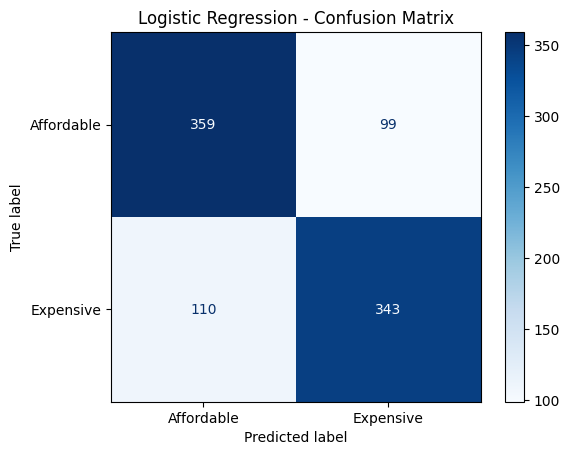

In [9]:
cm = confusion_matrix(y_test, predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Affordable", "Expensive"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Plot the training loss

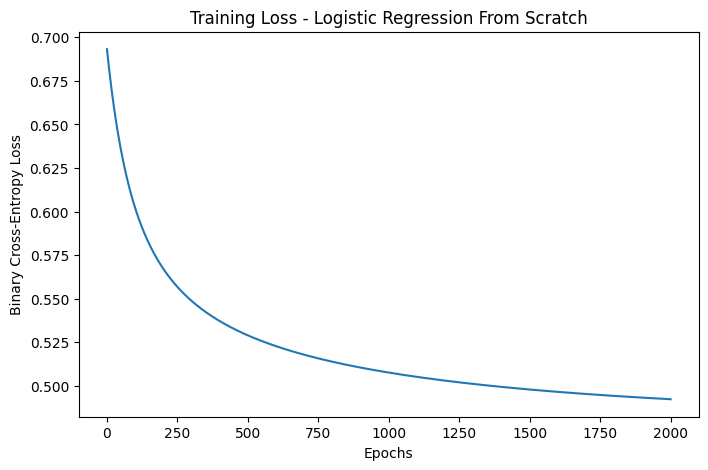

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(model.loss_history)

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss - Logistic Regression From Scratch")

plt.show()

Understand the learned weights

In [11]:
importance = pd.DataFrame({
    "Feature": features,
    "Weight": model.weights
})

importance["Absolute Weight"] = importance["Weight"].abs()

importance = importance.sort_values(
    by="Absolute Weight",
    ascending=False
)

print(importance)

        Feature    Weight  Absolute Weight
2   sqft_living  1.112145         1.112145
1     bathrooms  0.508016         0.508016
8      yr_built -0.491979         0.491979
4        floors  0.361729         0.361729
6          view  0.258062         0.258062
7     condition  0.202882         0.202882
5    waterfront  0.074101         0.074101
9  yr_renovated  0.049793         0.049793
3      sqft_lot  0.034502         0.034502
0      bedrooms -0.024010         0.024010
